# AI Data Classification Project
## DecodeLabs · Project 2 · Supervised Learning with K-Nearest Neighbors

**Goal:** build a basic classification model on a small dataset.

**Pipeline (Input → Process → Output):**
1. **Input:** load and understand the Iris dataset, then scale features
2. **Process:** train/test split, train KNN, tune K
3. **Output:** accuracy, confusion matrix, precision/recall/F1, and a comparison against Logistic Regression

## 1. Imports

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Load and understand the dataset

The Iris dataset is loaded from the CSV file `iris_classification.csv`. It has **150 samples**, **3 classes** (setosa, versicolor, virginica) and **4 numeric features** measured in cm: sepal length, sepal width, petal length, and petal width. Each class has 50 samples, so the data is balanced.

Make sure `iris_classification.csv` is in the same folder as this notebook (or upload it to the current Google Colab session).

In [15]:
df = pd.read_csv('/content/iris_classification.csv')

# Keep the same feature and target columns used throughout this notebook.
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
df = df[features + ['species']]

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [16]:
print('Shape:', df.shape)
print('\nData types / non-null counts:')
df.info()
print('\nClass distribution:')
print(df['species'].value_counts())
print('\nMissing values per column:')
print(df.isnull().sum())

Shape: (150, 5)

Data types / non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [17]:
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


**What we see:** no missing values, 50 samples per class, and all four features are numeric. Their ranges differ (petal width is roughly 0.1–2.5 cm while sepal length is roughly 4.3–7.9 cm), which matters for a distance-based algorithm like KNN. We handle that with scaling in section 4.

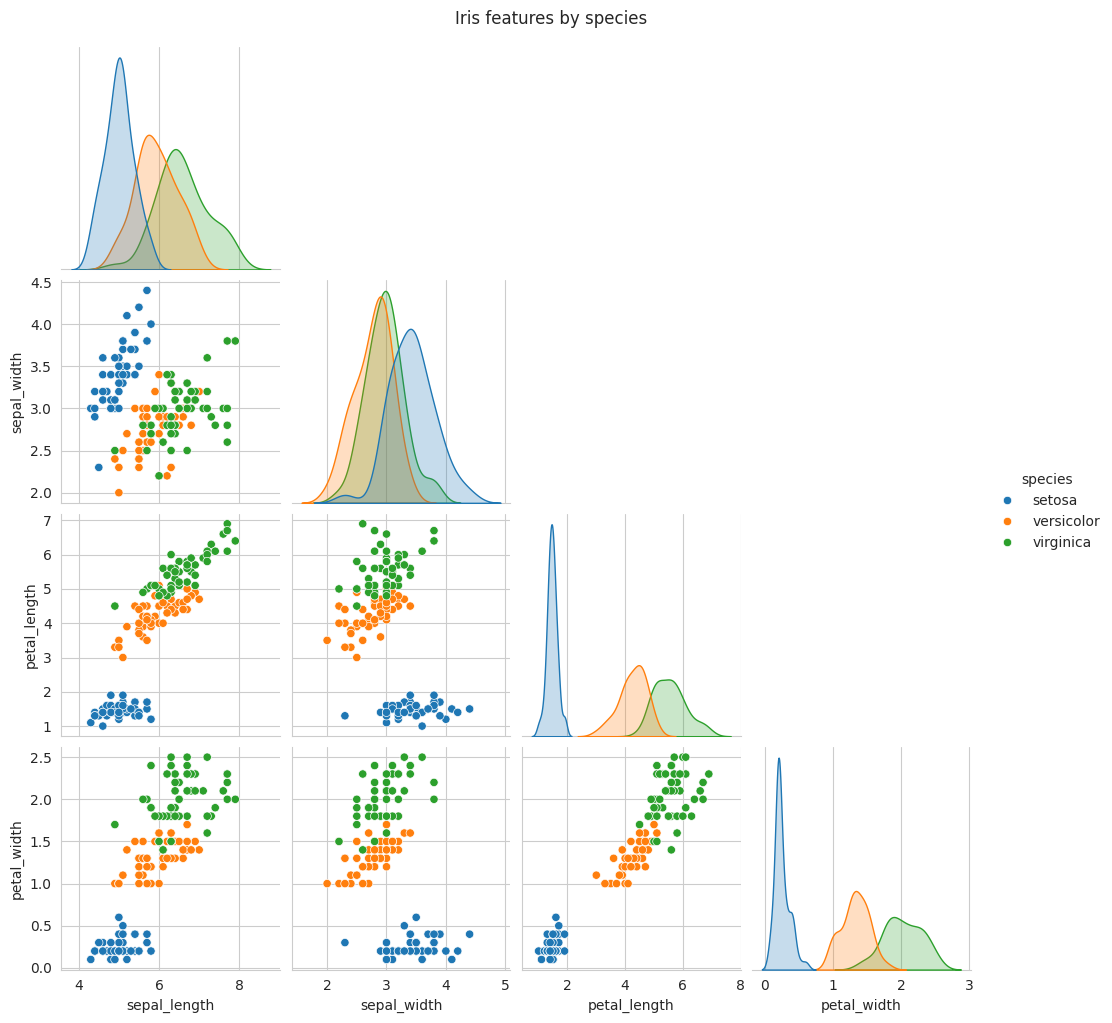

In [18]:
sns.pairplot(df, hue='species', corner=True)
plt.suptitle('Iris features by species', y=1.02)
plt.show()

The pair plot shows that **setosa** is clearly separated from the other two classes, while **versicolor** and **virginica** overlap somewhat. Petal length and petal width separate the classes best.

## 3. Train/test split

The data is split **80% train / 20% test**. `stratify=y` keeps the class proportions equal in both sets. `random_state` makes the result reproducible. `train_test_split` shuffles by default, which removes any order bias because the CSV is sorted by species. The test set stays untouched until the final evaluation.

In [19]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = df[features]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('\nTest class counts:')
print(y_test.value_counts())

Train: (120, 4)  Test: (30, 4)

Test class counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 4. Feature scaling

KNN decides by distance, so a feature with a larger numeric range would dominate. `StandardScaler` rescales each feature to mean 0 and variance 1.

The scaler is **fit on the training data only** and then applied to the test data. Fitting on the full dataset would leak information from the test set.

In [20]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Train mean (≈0):', X_train_s.mean(axis=0).round(2))
print('Train std  (≈1):', X_train_s.std(axis=0).round(2))

Train mean (≈0): [-0.  0.  0.  0.]
Train std  (≈1): [1. 1. 1. 1.]


## 5. Choosing K

- **Small K** (e.g. 1) follows noise and overfits.
- **Large K** over-smooths and underfits.

We pick K using **5-fold cross-validation on the training set only**, so the test set stays a fair final exam.

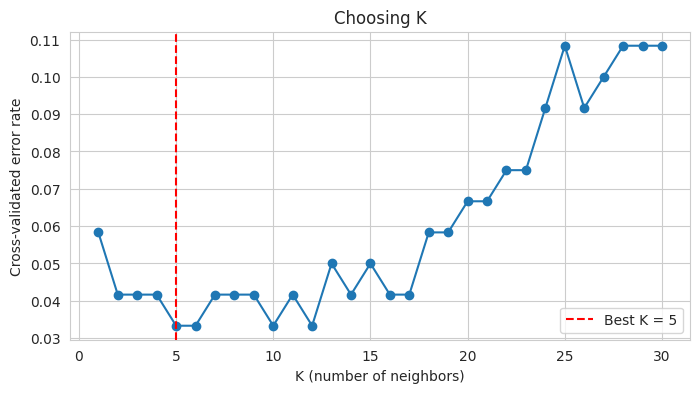

Best K: 5 | CV error: 0.0333


In [21]:
k_values = range(1, 31)
cv_errors = []
for k in k_values:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5)
    cv_errors.append(1 - scores.mean())

best_k = k_values[int(np.argmin(cv_errors))]

plt.figure(figsize=(8, 4))
plt.plot(k_values, cv_errors, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')
plt.xlabel('K (number of neighbors)')
plt.ylabel('Cross-validated error rate')
plt.title('Choosing K')
plt.legend()
plt.show()

print('Best K:', best_k, '| CV error:', round(min(cv_errors), 4))

## 6. Train the KNN model

scikit-learn follows three steps: **instantiate**, **fit**, **predict**.

In [22]:
model = KNeighborsClassifier(n_neighbors=best_k)   # instantiate
model.fit(X_train_s, y_train)                      # fit
predictions = model.predict(X_test_s)              # predict

print(f'K = {best_k}')
print('Test accuracy:', round(accuracy_score(y_test, predictions), 4))

K = 5
Test accuracy: 0.9333


## 7. Evaluation

Accuracy alone can mislead, especially on imbalanced data. The confusion matrix and the per-class precision, recall and F1 give a fuller picture.

In [23]:
print(classification_report(y_test, predictions))
print('Macro F1:', round(f1_score(y_test, predictions, average='macro'), 4))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Macro F1: 0.9327


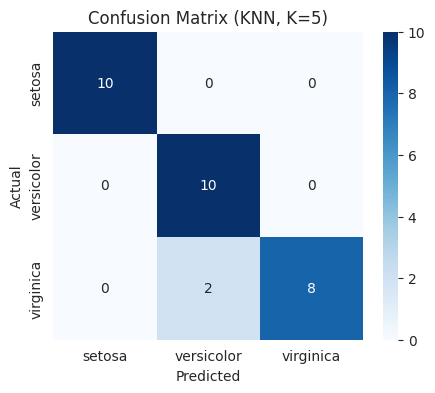

In [24]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, predictions, labels=labels)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix (KNN, K={best_k})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Reading the matrix:** the diagonal holds correct predictions. Any off-diagonal cell is a mistake. On Iris, errors almost always occur between *versicolor* and *virginica*, because those classes overlap.

## 8. Algorithm comparison: KNN vs Logistic Regression

The conclusion of the brief suggests comparing algorithms, so here is a second model on the same scaled split.

In [25]:
log_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_model.fit(X_train_s, y_train)
log_pred = log_model.predict(X_test_s)

comparison = pd.DataFrame({
    'Model': [f'KNN (K={best_k})', 'Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, predictions), accuracy_score(y_test, log_pred)],
    'Macro F1': [f1_score(y_test, predictions, average='macro'), f1_score(y_test, log_pred, average='macro')],
}).round(4)
comparison

,Model,Accuracy,Macro F1
0,KNN (K=5),0.9333,0.9327
1,Logistic Regression,0.9333,0.9333


## 9. Predict on completely new data

Testing on unseen measurements, as the brief recommends. New samples must go through the **same fitted scaler**.

In [26]:
new_samples = pd.DataFrame(
    [[5.0, 3.4, 1.5, 0.2],    # looks like setosa
     [6.0, 2.8, 4.5, 1.4],    # looks like versicolor
     [6.9, 3.1, 5.8, 2.1]],   # looks like virginica
    columns=features
)
new_pred = model.predict(scaler.transform(new_samples))
new_proba = model.predict_proba(scaler.transform(new_samples))

out = new_samples.copy()
out['predicted_species'] = new_pred
out['confidence'] = new_proba.max(axis=1).round(2)
out

,sepal_length,sepal_width,petal_length,petal_width,predicted_species,confidence
0,5.0,3.4,1.5,0.2,setosa,1.0
1,6.0,2.8,4.5,1.4,versicolor,1.0
2,6.9,3.1,5.8,2.1,virginica,1.0


## 10. Conclusion

- **Data:** Iris has 150 balanced samples, 3 classes, 4 features and no missing values.
- **Process:** the data was split 80/20 with stratification, scaled using training statistics only, and K was chosen by cross-validation on the training set.
- **Result:** with K=5 the KNN model reaches 93.3% accuracy (macro F1 ≈ 0.93) on the 30 held-out samples. Setosa is classified perfectly, and the few mistakes are between versicolor and virginica. Logistic Regression scores the same here, so on a test set this small the two models are effectively tied.
- **Takeaway:** scaling and a leak-free split matter as much as the algorithm. Next steps are other algorithms (decision trees, SVM) and, later, deep learning on images (CNNs).